# 03 — Graph-based ground cost over the 96 SBS channels

The Wasserstein / OT loss in NMF-OT needs a **ground cost** $C \in \mathbb{R}^{96\times 96}$: how expensive it is to move probability mass from one SBS channel to another.

**Approach 1 (previous work).** Cost as a linear combination of per-component changes of the trinucleotide `5'[REF>ALT]3'`:

$$C^{\text{lin}}_{ij} = a_5\,[5'_i \ne 5'_j] + a_{\text{sub}}\,[\text{sub}_i \ne \text{sub}_j] + a_3\,[3'_i \ne 3'_j].$$

**Approach 2 (this notebook).** Build a weighted graph $G$ whose **nodes are the 96 channels** and whose **edges are elementary moves** (change one component of the channel). The cost is the **shortest-path distance** in $G$:

$$C^{\text{graph}}_{ij} = \min_{\text{paths } i \to j} \sum_{(u,v)\in \text{path}} w_{uv}.$$

A shortest-path distance on a connected graph with positive weights is always a proper **metric** (symmetric, zero diagonal, triangle inequality), which is what makes $W_C$ a true Wasserstein distance.

**Why the graph is more than approach 1.** If every edge that changes component $k$ has the same weight $a_k$, the graph is a Cartesian product and shortest paths reduce *exactly* to approach 1 (checked in §4). The graph only adds something when edge weights depend on *which* change is made and *where*. Here that comes from three sources:

1. **A metric inside each component.** Flank changes are cheaper for transitions (A↔G, C↔T) than for transversions. The 6 substitution classes form their own small graph: moving between two transversions of the same reference base is cheaper than switching between transition and transversion, and switching the reference base (C vs T, different damage chemistry) is the most expensive move.
2. **Context-dependent edges.** Moving a C>N channel into or out of the CpG context (3' base = G) costs extra, because CpG is mechanistically special (methyl-C deamination, SBS1). The weight of a flank move then depends on the substitution, so the cost no longer separates by component.
3. **Data-informed weights (optional).** Each edge is shortened in proportion to how strongly its two channels co-vary across real tumour spectra (PCAWG). Shortest paths can then route through channels that co-occur biologically.

**Plugging in your own biochemistry.** Edge weights come from a *weight function* `weight_fn(u, v, kind)`. §5 builds one from 4×4 base-to-base **energy tables** (CSV files in `data/energy/`), with optional per-position tables, a 6×6 substitution-class table, context hooks and per-edge overrides. Any other rule can be dropped in the same way.

> **Interpretation note.** The earlier cost-matrix work lives in another Claude project and is not in this folder, so the edge rules and weights below are my reconstruction of "approach 2". Every number is in the parameter cell (§1) and marked `# ASSUMPTION`; change them to match the earlier definition.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import MDS

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="ticks", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Resolve data/ whether the notebook is run from the repo root or a subfolder
DATA = next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
OUT = DATA / "cost_matrix"
OUT.mkdir(exist_ok=True)

# Standard COSMIC colours for the six substitution classes
SUBS = ["C>A", "C>G", "C>T", "T>A", "T>C", "T>G"]
SUB_COLORS = dict(zip(SUBS, ["#1ebff0", "#050708", "#e62725", "#cbcacb", "#a1cf64", "#edc8c5"]))
BASES = ["A", "C", "G", "T"]

# Canonical COSMIC channel order (same as CHANNELS in 01_EDA): by substitution, then 5' base, then 3' base
CHANNELS = pd.Index([f"{f}[{s}]{t}" for s in SUBS for f in BASES for t in BASES], name="MutationType")
channels = pd.DataFrame({
    "five": CHANNELS.str[0], "sub": CHANNELS.str[2:5], "three": CHANNELS.str[-1],
    "ref": CHANNELS.str[2], "alt": CHANNELS.str[4],
}, index=CHANNELS)
SUB_OF = channels["sub"].to_numpy(dtype=str)
IDX = {c: i for i, c in enumerate(CHANNELS)}
len(CHANNELS)

96

## 1. Parameters

All edge weights of the graph. Flank moves have base weight `W_FLANK`, substitution moves base weight `W_SUB`; both are multiplied by the factors below.

In [2]:
# ---- Flank moves: change the 5' or 3' base, keep everything else ----------------------------
W_FLANK = 1.0          # ASSUMPTION: base cost of changing one flanking base
W5, W3 = 1.0, 1.0      # ASSUMPTION: relative weight of 5' vs 3' flank (set W3 > W5 to make the 3' base matter more)
FLANK_TV = 1.25        # ASSUMPTION: multiplier for a transversion flank change (A/G <-> C/T) vs a transition (A<->G, C<->T)
CPG_FACTOR = 1.5       # ASSUMPTION: multiplier for a 3' move into/out of G on a C>N channel (entering/leaving CpG)

# ---- Substitution moves: change REF and/or ALT, keep both flanks ---------------------------
W_SUB = 2.0            # ASSUMPTION: base cost of changing the substitution class (substitution > flank)
# Edges of the 6-node substitution-class graph, as multipliers of W_SUB. Pairs not listed are not adjacent.
SUB_EDGES = {          # ASSUMPTION: all values
    ("C>A", "C>G"): 1.0,   # same REF, both transversions
    ("T>A", "T>G"): 1.0,   # same REF, both transversions
    ("C>A", "C>T"): 1.5,   # same REF, transversion <-> transition
    ("C>G", "C>T"): 1.5,
    ("T>A", "T>C"): 1.5,
    ("T>G", "T>C"): 1.5,
    ("C>A", "T>A"): 2.0,   # same ALT, REF switches C <-> T (different damage chemistry)
    ("C>G", "T>G"): 2.0,
    ("C>T", "T>C"): 2.0,   # the two transition classes
}

# ---- Data-informed reweighting (approach 2c) ------------------------------------------------
LAMBDA = 0.5           # ASSUMPTION: w_ij <- w_ij * (1 - LAMBDA * s_ij), s_ij = positive co-variation of channels i, j
MIN_SBS = 100          # samples with fewer SBS are too noisy to estimate co-variation (as in 01_EDA §6.2)
K_EXTRA = 0            # optional: also connect each channel to its K most co-varying *non-adjacent* channels
EXTRA_BASE = 3.0       # ASSUMPTION: base weight of such an extra edge (before the (1 - LAMBDA * s) factor)

PARAMS = {k: v for k, v in dict(globals()).items()
          if k in {"W_FLANK", "W5", "W3", "FLANK_TV", "CPG_FACTOR", "W_SUB", "LAMBDA", "MIN_SBS", "K_EXTRA", "EXTRA_BASE"}}
PARAMS["SUB_EDGES"] = {f"{a}--{b}": w for (a, b), w in SUB_EDGES.items()}
PARAMS

{'W_FLANK': 1.0,
 'W5': 1.0,
 'W3': 1.0,
 'FLANK_TV': 1.25,
 'CPG_FACTOR': 1.5,
 'W_SUB': 2.0,
 'LAMBDA': 0.5,
 'MIN_SBS': 100,
 'K_EXTRA': 0,
 'EXTRA_BASE': 3.0,
 'SUB_EDGES': {'C>A--C>G': 1.0,
  'T>A--T>G': 1.0,
  'C>A--C>T': 1.5,
  'C>G--C>T': 1.5,
  'T>A--T>C': 1.5,
  'T>G--T>C': 1.5,
  'C>A--T>A': 2.0,
  'C>G--T>G': 2.0,
  'C>T--T>C': 2.0}}

## 2. Building the graph

The graph is built in two steps so the weighting rule can be swapped:

1. `build_edges(weight_fn, sub_pairs)` enumerates every **directed** move `u → v` (one flank base, or the substitution class along an allowed pair) and asks `weight_fn(u, v, kind)` for its weight. Returning `NaN`/`inf` drops the move.
2. Optional `overrides` replace or add individual edges, then `symmetrize` merges `u → v` and `v → u` (`"mean"`, `"min"`, `"max"`, or `None` to keep a directed graph and an asymmetric cost).

Edges are a tidy table (`u`, `v`, `weight`, `kind`) holding both directions, so every move can be inspected.

In [3]:
TRANSITION = {frozenset("AG"), frozenset("CT")}

def is_transition(a, b):
    return frozenset((a, b)) in TRANSITION


def heuristic_weight(w_flank=W_FLANK, w5=W5, w3=W3, flank_tv=FLANK_TV, cpg=CPG_FACTOR, w_sub=W_SUB, sub_edges=SUB_EDGES):
    # weight_fn implementing the hand-set rules of §1
    def fn(u, v, kind):
        cu, cv = channels.loc[u], channels.loc[v]
        if kind == "substitution":
            m = sub_edges.get((cu["sub"], cv["sub"]), sub_edges.get((cv["sub"], cu["sub"])))
            return w_sub * m
        side = kind.removeprefix("flank_")
        w = w_flank * (w5 if side == "five" else w3)
        if not is_transition(cu[side], cv[side]):
            w *= flank_tv
        # Entering / leaving the CpG context: C>N channel whose 3' base changes to or from G
        if side == "three" and cu["ref"] == "C" and "G" in (cu[side], cv[side]):
            w *= cpg
        return w
    return fn


def build_edges(weight_fn, sub_pairs=SUB_EDGES, overrides=None, symmetrize="mean"):
    rows = []
    for u in CHANNELS:
        f, s, t = channels.loc[u, ["five", "sub", "three"]]
        moves = [(f"{b}[{s}]{t}", "flank_five") for b in BASES if b != f]
        moves += [(f"{f}[{s}]{b}", "flank_three") for b in BASES if b != t]
        moves += [(f"{f}[{b if s == a else a}]{t}", "substitution") for a, b in sub_pairs if s in (a, b)]
        rows += [(u, v, weight_fn(u, v, kind), kind) for v, kind in moves]
    E = pd.DataFrame(rows, columns=["u", "v", "weight", "kind"])

    if overrides is not None and len(overrides):
        ov = overrides.assign(kind=overrides.get("kind", "override"))[["u", "v", "weight", "kind"]]
        bad = set(ov.u) | set(ov.v)
        assert bad <= set(CHANNELS), f"unknown channels in overrides: {bad - set(CHANNELS)}"
        E = pd.concat([E, ov]).drop_duplicates(["u", "v"], keep="last")

    E = E[np.isfinite(E.weight.astype(float))].reset_index(drop=True)
    assert (E.weight > 0).all(), "edge weights must be positive (shift or transform your energies)"

    if symmetrize:
        rev = E.set_index(["v", "u"]).weight.rename_axis(["u", "v"])
        w_rev = rev.reindex(pd.MultiIndex.from_frame(E[["u", "v"]])).values
        both = np.vstack([E.weight.values, np.where(np.isnan(w_rev), E.weight.values, w_rev)])
        E["weight"] = {"mean": both.mean(0), "min": both.min(0), "max": both.max(0)}[symmetrize]
        # a one-way edge (e.g. from an override) becomes two-way
        missing = E[np.isnan(w_rev)].rename(columns={"u": "v", "v": "u"})
        E = pd.concat([E, missing], ignore_index=True)
    return E


E_struct = build_edges(heuristic_weight())
print(f"{len(E_struct)} directed moves ({len(E_struct) // 2} undirected edges); per kind:")
display(E_struct.groupby("kind").weight.describe()[["count", "min", "max"]])
print("out-degree of every node:", E_struct.u.value_counts().unique())

864 directed moves (432 undirected edges); per kind:


,count,min,max
kind,,,
flank_five,288.0,1.0,1.250
flank_three,288.0,1.0,1.875
substitution,288.0,2.0,4.000


out-degree of every node: [9]


Each channel has 6 flank neighbours (3 per side) and, with the default `SUB_EDGES`, 3 substitution neighbours, so the graph is 9-regular.

### 2.1 The substitution-class graph

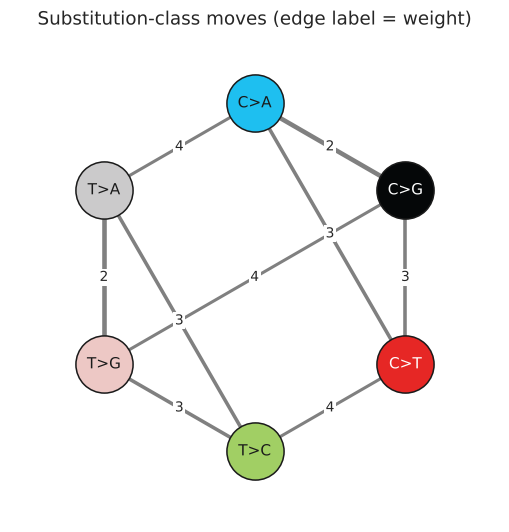

In [4]:
pos = {s: (np.cos(a), np.sin(a)) for s, a in zip(["C>A", "C>G", "C>T", "T>C", "T>G", "T>A"],
                                               np.pi / 2 - np.arange(6) * np.pi / 3)}
fig, ax = plt.subplots(figsize=(5, 5))
for (a, b), m in SUB_EDGES.items():
    (x1, y1), (x2, y2) = pos[a], pos[b]
    ax.plot([x1, x2], [y1, y2], c="grey", lw=1 + 2 / m, zorder=1)
    ax.text((x1 + x2) / 2, (y1 + y2) / 2, f"{W_SUB * m:g}", fontsize=9, ha="center", va="center",
            bbox=dict(fc="white", ec="none", pad=1))
for s, (x, y) in pos.items():
    ax.scatter(x, y, s=1400, color=SUB_COLORS[s], edgecolor="k", zorder=2)
    ax.text(x, y, s, ha="center", va="center", fontsize=10, color="white" if s in ("C>G", "C>T") else "k", zorder=3)
ax.set(xlim=(-1.4, 1.4), ylim=(-1.4, 1.4), title="Substitution-class moves (edge label = weight)")
ax.set_aspect("equal"); ax.axis("off")
plt.tight_layout()

## 3. Shortest-path cost

96 nodes is small, so Floyd–Warshall in numpy is instant and needs no graph library. It works on directed graphs too. A next-hop matrix is kept so any optimal path can be printed.

In [5]:
def adjacency(E, n=96):
    A = np.full((n, n), np.inf)
    np.fill_diagonal(A, 0.0)
    for u, v, w in zip(E.u.map(IDX), E.v.map(IDX), E.weight):
        A[u, v] = min(A[u, v], w)
    return A


def floyd_warshall(A):
    D = A.copy()
    n = len(D)
    nxt = np.where(np.isfinite(A), np.arange(n)[None, :], -1)
    for k in range(n):
        via = D[:, [k]] + D[[k], :]
        better = via < D - 1e-12
        D = np.where(better, via, D)
        nxt = np.where(better, nxt[:, [k]], nxt)
    return D, nxt


def shortest_path_cost(E):
    D, nxt = floyd_warshall(adjacency(E))
    return as_cost(D), nxt


def path(nxt, i, j):
    i, j = IDX[i], IDX[j]
    out = [CHANNELS[i]]
    while i != j:
        i = nxt[i, j]
        out.append(CHANNELS[i])
    return out


def as_cost(D):
    assert np.isfinite(D).all(), "graph is disconnected"
    return pd.DataFrame(D, index=CHANNELS, columns=CHANNELS)


D_struct, NXT_struct = floyd_warshall(adjacency(E_struct))
C_struct = as_cost(D_struct)
print("distinct cost values:", np.unique(C_struct.values.round(6)).size, " max:", C_struct.values.max())

distinct cost values: 38  max: 9.5


In [6]:
for a, b in [("A[C>T]G", "A[C>T]A"), ("A[C>T]G", "T[T>A]T"), ("C[C>A]A", "T[T>G]G"), ("T[C>T]G", "T[T>C]G")]:
    p = path(NXT_struct, a, b)
    print(f"{a} -> {b}   cost={C_struct.at[a, b]:.2f}   path: {' -> '.join(p)}")

A[C>T]G -> A[C>T]A   cost=1.50   path: A[C>T]G -> A[C>T]A
A[C>T]G -> T[T>A]T   cost=9.50   path: A[C>T]G -> A[C>A]G -> A[T>A]G -> A[T>A]T -> T[T>A]T
C[C>A]A -> T[T>G]G   cost=8.00   path: C[C>A]A -> C[T>A]A -> C[T>A]G -> T[T>A]G -> T[T>G]G
T[C>T]G -> T[T>C]G   cost=4.00   path: T[C>T]G -> T[T>C]G


## 4. Approach 1 as a special case

With uniform weights (no transition/transversion distinction, no CpG factor, every substitution move costing the same) the graph distance must equal the linear-combination cost. This checks the construction and makes clear that everything the graph adds comes from §1's non-uniform weights.

Note the substitution indicator: in approach 1 every pair of different substitution classes costs $a_{\text{sub}}$, so the uniform substitution graph must be **complete** (all 15 pairs adjacent).

In [7]:
def linear_cost(a5=W_FLANK * W5, a_sub=W_SUB, a3=W_FLANK * W3):
    diff = lambda col: (lambda x: x[:, None] != x[None, :])(channels[col].to_numpy(dtype=str))
    return pd.DataFrame(
        a5 * diff("five") + a_sub * diff("sub") + a3 * diff("three"),
        index=CHANNELS, columns=CHANNELS)


C_linear = linear_cost()

complete_sub = {(a, b): 1.0 for i, a in enumerate(SUBS) for b in SUBS[i + 1:]}
E_uniform = build_edges(heuristic_weight(flank_tv=1.0, cpg=1.0, sub_edges=complete_sub), sub_pairs=complete_sub)
C_uniform = as_cost(floyd_warshall(adjacency(E_uniform))[0])
print("uniform graph == approach 1:", np.allclose(C_uniform.values, C_linear.values))

uniform graph == approach 1: True


## 5. Biochemically informed weights: energy tables

If you can assign an **energy to changing one base into another** (e.g. a free-energy difference or an activation barrier, in any consistent unit), each move's weight is read from that table instead of the hand-set multipliers of §1.

**Inputs** (all optional; put them in `data/energy/`, rows = *from* base, columns = *to* base, index/columns `A C G T`):

| file | used for |
|---|---|
| `base_energy.csv` | default table for every role |
| `base_energy_five.csv`, `base_energy_three.csv` | 5' / 3' flank changes (override the default) |
| `base_energy_ref.csv`, `base_energy_alt.csv` | changing the REF or ALT base of the substitution |
| `sub_energy.csv` | 6×6 table over `C>A … T>G`; if present it replaces the REF/ALT composition for substitution moves, and a blank cell means "not adjacent" |
| `edge_overrides.csv` | columns `u, v, weight` (optionally `kind`): set any single move directly, e.g. a measured context-specific rate; `inf` removes an edge |

Without files, an **illustrative** table is used (made-up numbers, slightly asymmetric so C→T is easier than T→C) and a template is written to `data/energy/base_energy_template.csv` to fill in.

**From energy to edge weight.** `ENERGY_TO_COST` maps an energy to a positive weight. If the energy is an activation barrier $E$, a transition probability scales as $e^{-E/kT}$, so $-\log p \propto E/kT$: a **linear** map makes the shortest path the *most probable sequence of changes*, which is the default. A substitution move that changes REF and ALT at once (C>T ↔ T>C) adds the two energies. `ROLE_WEIGHT` scales the roles against each other, `CONTEXT_FN(u, v, kind, w)` can adjust any move by its full trinucleotide context (CpG, for example).

**Direction.** Energy tables can be asymmetric, so `u → v` and `v → u` can differ. `SYMMETRIZE` decides: `"mean"` (default) gives a proper metric and a true Wasserstein distance; `None` keeps the asymmetric cost (still usable in Sinkhorn, but no longer a metric).

In [8]:
ENERGY_DIR = DATA / "energy"
ROLES = ["five", "three", "ref", "alt"]

# ILLUSTRATIVE ONLY, not measured values: transitions cheaper than transversions, C->T slightly easier than T->C
EXAMPLE_ENERGY = pd.DataFrame([[0.0, 1.6, 1.0, 1.7],
                               [1.6, 0.0, 1.8, 0.9],
                               [1.0, 1.8, 0.0, 1.5],
                               [1.7, 1.3, 1.5, 0.0]], index=BASES, columns=BASES)

ROLE_WEIGHT = {"five": 1.0, "three": 1.0, "ref": 2.0, "alt": 2.0}  # ASSUMPTION: substitution energies count double vs flanks
ENERGY_TO_COST = lambda e: e                                       # e.g. lambda e: e - E_MIN + 0.1  to shift negative energies
CONTEXT_FN = None                                                  # e.g. cpg_context below
SYMMETRIZE = "mean"


def cpg_context(u, v, kind, w, factor=CPG_FACTOR):
    # example context hook: entering/leaving CpG on a C>N channel costs `factor` times more
    cu, cv = channels.loc[u], channels.loc[v]
    return w * factor if kind == "flank_three" and cu["ref"] == "C" and "G" in (cu["three"], cv["three"]) else w


def read_table(path, labels):
    T = pd.read_csv(path, index_col=0).astype(float)
    T.index = T.index.astype(str).str.strip(); T.columns = T.columns.astype(str).str.strip()
    assert set(T.index) == set(T.columns) == set(labels), f"{path.name}: index/columns must be {labels}"
    return T.loc[labels, labels]


def load_energies(energy_dir=ENERGY_DIR):
    energy_dir.mkdir(exist_ok=True)
    default = energy_dir / "base_energy.csv"
    base = read_table(default, BASES) if default.exists() else EXAMPLE_ENERGY
    energy, source = {}, {}
    for r in ROLES:
        f = energy_dir / f"base_energy_{r}.csv"
        energy[r] = read_table(f, BASES) if f.exists() else base
        source[r] = f.name if f.exists() else (default.name if default.exists() else "EXAMPLE_ENERGY (illustrative)")
    f = energy_dir / "sub_energy.csv"
    sub_energy = read_table(f, SUBS) if f.exists() else None
    f = energy_dir / "edge_overrides.csv"
    overrides = pd.read_csv(f) if f.exists() else None
    if not (energy_dir / "base_energy_template.csv").exists():
        EXAMPLE_ENERGY.rename_axis("from\\to").to_csv(energy_dir / "base_energy_template.csv")
    return energy, sub_energy, overrides, source


def energy_weight(energy, sub_energy=None, role_weight=ROLE_WEIGHT, to_cost=ENERGY_TO_COST, context_fn=CONTEXT_FN):
    # weight_fn reading each move's energy from the tables
    def fn(u, v, kind):
        cu, cv = channels.loc[u], channels.loc[v]
        if kind.startswith("flank"):
            side = kind.removeprefix("flank_")
            e = role_weight[side] * energy[side].at[cu[side], cv[side]]
        elif sub_energy is not None:
            e = sub_energy.at[cu["sub"], cv["sub"]]
        else:
            e = sum(role_weight[r] * energy[r].at[cu[r], cv[r]] for r in ("ref", "alt") if cu[r] != cv[r])
        w = to_cost(e)
        return context_fn(u, v, kind, w) if context_fn else w
    return fn


energy, sub_energy, overrides, source = load_energies()
print("energy source per role:", source)
print("sub_energy.csv:", "used" if sub_energy is not None else "not provided", "| edge_overrides.csv:",
      f"{len(overrides)} rows" if overrides is not None else "not provided")
display(energy["ref"].style.format("{:.2f}").set_caption("energy table (ref role)"))

# adjacent substitution classes: from sub_energy if given (non-blank cells), else SUB_EDGES
sub_pairs = ([(a, b) for a in SUBS for b in SUBS if a < b and np.isfinite(sub_energy.at[a, b])]
             if sub_energy is not None else list(SUB_EDGES))
w_fn = energy_weight(energy, sub_energy)

E_energy = build_edges(w_fn, sub_pairs, overrides, symmetrize=SYMMETRIZE)
C_energy, NXT_energy = shortest_path_cost(E_energy)

E_energy_dir = build_edges(w_fn, sub_pairs, overrides, symmetrize=None)
C_energy_dir, NXT_energy_dir = shortest_path_cost(E_energy_dir)
asym = np.abs(C_energy_dir.values - C_energy_dir.values.T).max()
print(f"symmetrised cost max = {C_energy.values.max():.2f}; directed version max |C_ij - C_ji| = {asym:.2f}")

energy source per role: {'five': 'EXAMPLE_ENERGY (illustrative)', 'three': 'EXAMPLE_ENERGY (illustrative)', 'ref': 'EXAMPLE_ENERGY (illustrative)', 'alt': 'EXAMPLE_ENERGY (illustrative)'}
sub_energy.csv: not provided | edge_overrides.csv: not provided


,A,C,G,T
A,0.00,1.60,1.00,1.70
C,1.60,0.00,1.80,0.90
G,1.00,1.80,0.00,1.50
T,1.70,1.30,1.50,0.00


symmetrised cost max = 9.40; directed version max |C_ij - C_ji| = 1.60


In [9]:
for a, b in [("A[C>T]G", "T[T>A]T"), ("T[C>A]T", "T[T>C]T")]:
    print(f"{a} -> {b}")
    print(f"   heuristic          {C_struct.at[a, b]:.2f}: {' -> '.join(path(NXT_struct, a, b))}")
    print(f"   energy (sym.)      {C_energy.at[a, b]:.2f}: {' -> '.join(path(NXT_energy, a, b))}")
    print(f"   energy (directed)  {C_energy_dir.at[a, b]:.2f} forward, {C_energy_dir.at[b, a]:.2f} backward")

A[C>T]G -> T[T>A]T
   heuristic          9.50: A[C>T]G -> A[C>A]G -> A[T>A]G -> A[T>A]T -> T[T>A]T
   energy (sym.)      8.80: A[C>T]G -> A[C>A]G -> A[C>A]T -> T[C>A]T -> T[T>A]T
   energy (directed)  8.40 forward, 9.20 backward
T[C>A]T -> T[T>C]T
   heuristic          7.00: T[C>A]T -> T[C>T]T -> T[T>C]T
   energy (sym.)      5.40: T[C>A]T -> T[T>A]T -> T[T>C]T
   energy (directed)  5.00 forward, 5.80 backward


The data-informed reweighting of §6 takes any edge table, so it can be stacked on the energy graph as well: `reweight(E_energy, S)`.

## 6. Data-informed edge weights

$s_{ij}$ = positive part of the Pearson correlation between channels $i$ and $j$ across normalised PCAWG WGS profiles (samples with ≥ `MIN_SBS` SBS). Each existing edge is shortened to $w_{ij}(1-\lambda s_{ij})$, so moves between channels that rise and fall together across tumours become cheaper.

PCAWG is used instead of the COSMIC signatures on purpose: the simulations in `02_*` are generated from COSMIC, so a COSMIC-derived cost would leak the ground truth into the loss.

In [10]:
X = pd.read_csv(DATA / "PCAWG_WGS_SBS96_catalog.csv", index_col=0).loc[CHANNELS]
X = X.loc[:, X.sum() >= MIN_SBS]
P = X / X.sum()
S = np.clip(np.corrcoef(P.values), 0, None)
np.fill_diagonal(S, 0)
S = pd.DataFrame(S, index=CHANNELS, columns=CHANNELS)
print(f"{P.shape[1]} PCAWG samples used; share of channel pairs with positive correlation: {(S.values > 0).mean():.1%}")


def reweight(E, S, lam=LAMBDA, k_extra=K_EXTRA, extra_base=EXTRA_BASE):
    E = E.copy()
    s = S.values[E.u.map(IDX), E.v.map(IDX)]
    E["similarity"] = s
    E["weight"] = E.weight * (1 - lam * s)
    if k_extra:
        adj = np.isfinite(adjacency(E))
        rows = []
        for i in range(96):
            cand = [j for j in np.argsort(-S.values[i]) if not adj[i, j]][:k_extra]
            for j in cand:
                w = extra_base * (1 - lam * S.values[i, j])
                rows += [(CHANNELS[i], CHANNELS[j], w, "data_extra", S.values[i, j]),
                         (CHANNELS[j], CHANNELS[i], w, "data_extra", S.values[i, j])]
        E = pd.concat([E, pd.DataFrame(rows, columns=E.columns)]).drop_duplicates(["u", "v"]).reset_index(drop=True)
    return E


E_data = reweight(E_struct, S)
D_data, NXT_data = floyd_warshall(adjacency(E_data))
C_data = as_cost(D_data)

display(E_data[E_data.u.map(IDX) < E_data.v.map(IDX)].sort_values("similarity", ascending=False).head(10))

2750 PCAWG samples used; share of channel pairs with positive correlation: 56.0%


,u,v,weight,kind,similarity
257,T[C>G]A,T[C>G]T,0.641252,flank_three,0.973998
784,C[T>G]T,G[T>G]T,0.658345,flank_five,0.946648
401,T[C>T]A,T[C>T]T,0.661487,flank_three,0.941620
306,A[C>T]G,C[C>T]G,0.673718,flank_five,0.922052
307,A[C>T]G,G[C>T]G,0.545960,flank_five,0.908079
343,C[C>T]G,G[C>T]G,0.682601,flank_five,0.907838
646,C[T>C]T,C[T>G]T,1.669549,substitution,0.886967
749,A[T>G]T,T[T>G]T,0.709132,flank_five,0.865389
472,C[T>A]A,C[T>A]G,0.572358,flank_three,0.855284
327,C[C>T]A,C[C>T]C,0.729609,flank_three,0.832626


In [11]:
for a, b in [("A[C>T]G", "T[C>T]G"), ("T[C>T]A", "T[C>G]A"), ("A[C>T]G", "T[T>A]T")]:
    print(f"{a} -> {b}")
    print(f"   structural  {C_struct.at[a, b]:.2f}: {' -> '.join(path(NXT_struct, a, b))}")
    print(f"   data-aware  {C_data.at[a, b]:.2f}: {' -> '.join(path(NXT_data, a, b))}")

A[C>T]G -> T[C>T]G
   structural  1.25: A[C>T]G -> T[C>T]G
   data-aware  0.86: A[C>T]G -> T[C>T]G
T[C>T]A -> T[C>G]A
   structural  3.00: T[C>T]A -> T[C>G]A
   data-aware  2.05: T[C>T]A -> T[C>G]A
A[C>T]G -> T[T>A]T
   structural  9.50: A[C>T]G -> A[C>A]G -> A[T>A]G -> A[T>A]T -> T[T>A]T
   data-aware  8.25: A[C>T]G -> A[C>A]G -> A[T>A]G -> T[T>A]G -> T[T>A]T


## 7. Checks and comparison

In [12]:
def check_metric(C, name):
    M = C.values
    tri = (M[:, :, None] <= M[:, None, :] + M.T[None, :, :] + 1e-9)  # C_ik <= C_ij + C_jk
    return {"name": name, "symmetric": np.allclose(M, M.T), "zero diagonal": np.allclose(np.diag(M), 0),
            "positive off-diag": (M[~np.eye(96, dtype=bool)] > 0).all(), "triangle inequality": tri.all(),
            "min off-diag": M[~np.eye(96, dtype=bool)].min(), "max": M.max(),
            "distinct values": np.unique(M.round(6)).size}

COSTS = {"linear (approach 1)": C_linear, "graph: structural": C_struct, "graph: energy": C_energy, "graph: data-aware": C_data}
check = pd.DataFrame([check_metric(C, k) for k, C in {**COSTS, "graph: energy, directed": C_energy_dir}.items()]).set_index("name")
check

,symmetric,zero diagonal,positive off-diag,triangle inequality,min off-diag,max,distinct values
name,,,,,,,
linear (approach 1),True,True,True,True,1.00000,4.000000,5
graph: structural,True,True,True,True,1.00000,9.500000,38
graph: energy,True,True,True,True,1.00000,9.400000,80
graph: data-aware,True,True,True,True,0.54596,8.535208,4364
"graph: energy, directed",False,True,True,True,0.90000,9.800000,87


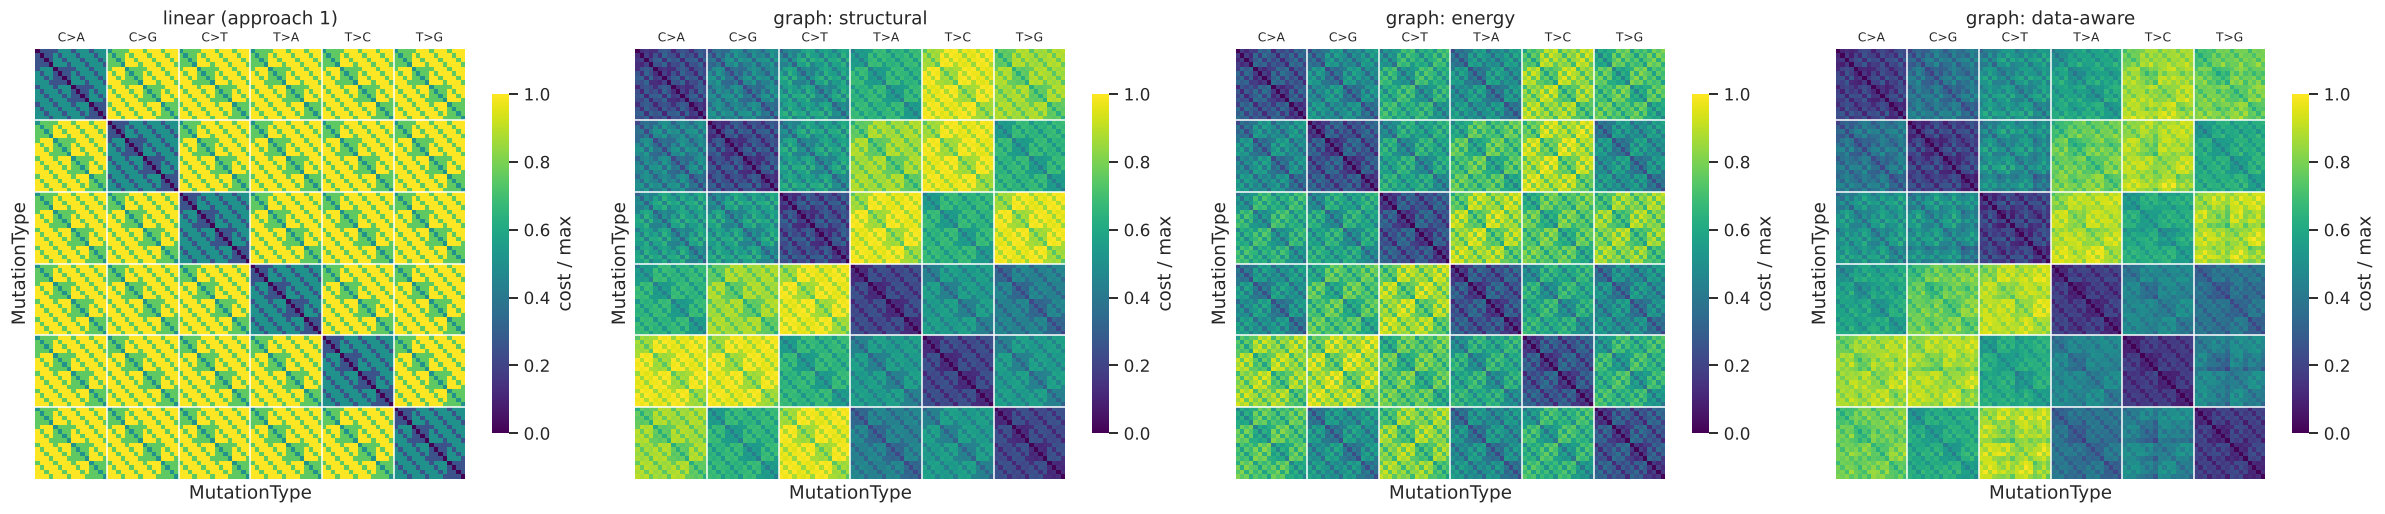

In [13]:
def cost_heatmap(C, ax, title):
    sns.heatmap(C / C.values.max(), ax=ax, cmap="viridis", square=True, xticklabels=False, yticklabels=False,
                cbar_kws={"shrink": 0.6, "label": "cost / max"})
    for i in range(1, 6):
        ax.axvline(16 * i, c="white", lw=1); ax.axhline(16 * i, c="white", lw=1)
    for i, s in enumerate(SUBS):
        ax.text(16 * i + 8, -1, s, ha="center", va="bottom", fontsize=8)
    ax.set_title(title, pad=16)

fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
for ax, (k, C) in zip(axes, COSTS.items()):
    cost_heatmap(C, ax, k)
plt.tight_layout()

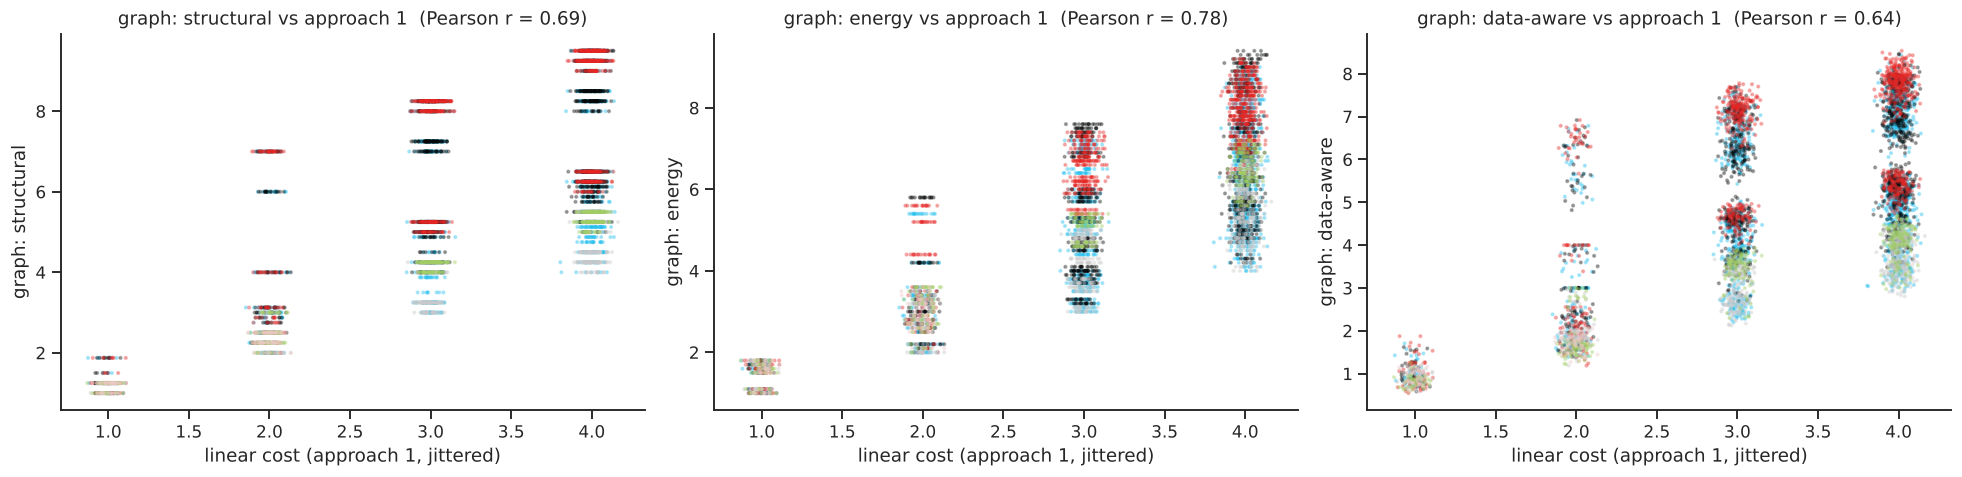

In [14]:
iu = np.triu_indices(96, 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, k in zip(axes, ["graph: structural", "graph: energy", "graph: data-aware"]):
    x = C_linear.values[iu]; y = COSTS[k].values[iu]
    ax.scatter(x + np.random.default_rng(0).normal(0, 0.05, x.size), y, s=3, alpha=0.3,
               c=[SUB_COLORS[s] for s in SUB_OF[iu[0]]])
    r = np.corrcoef(x, y)[0, 1]
    ax.set(xlabel="linear cost (approach 1, jittered)", ylabel=k, title=f"{k} vs approach 1  (Pearson r = {r:.2f})")
plt.tight_layout()

### 7.1 Geometry of the channels

Metric MDS of each cost matrix: channels close together are cheap to move mass between.

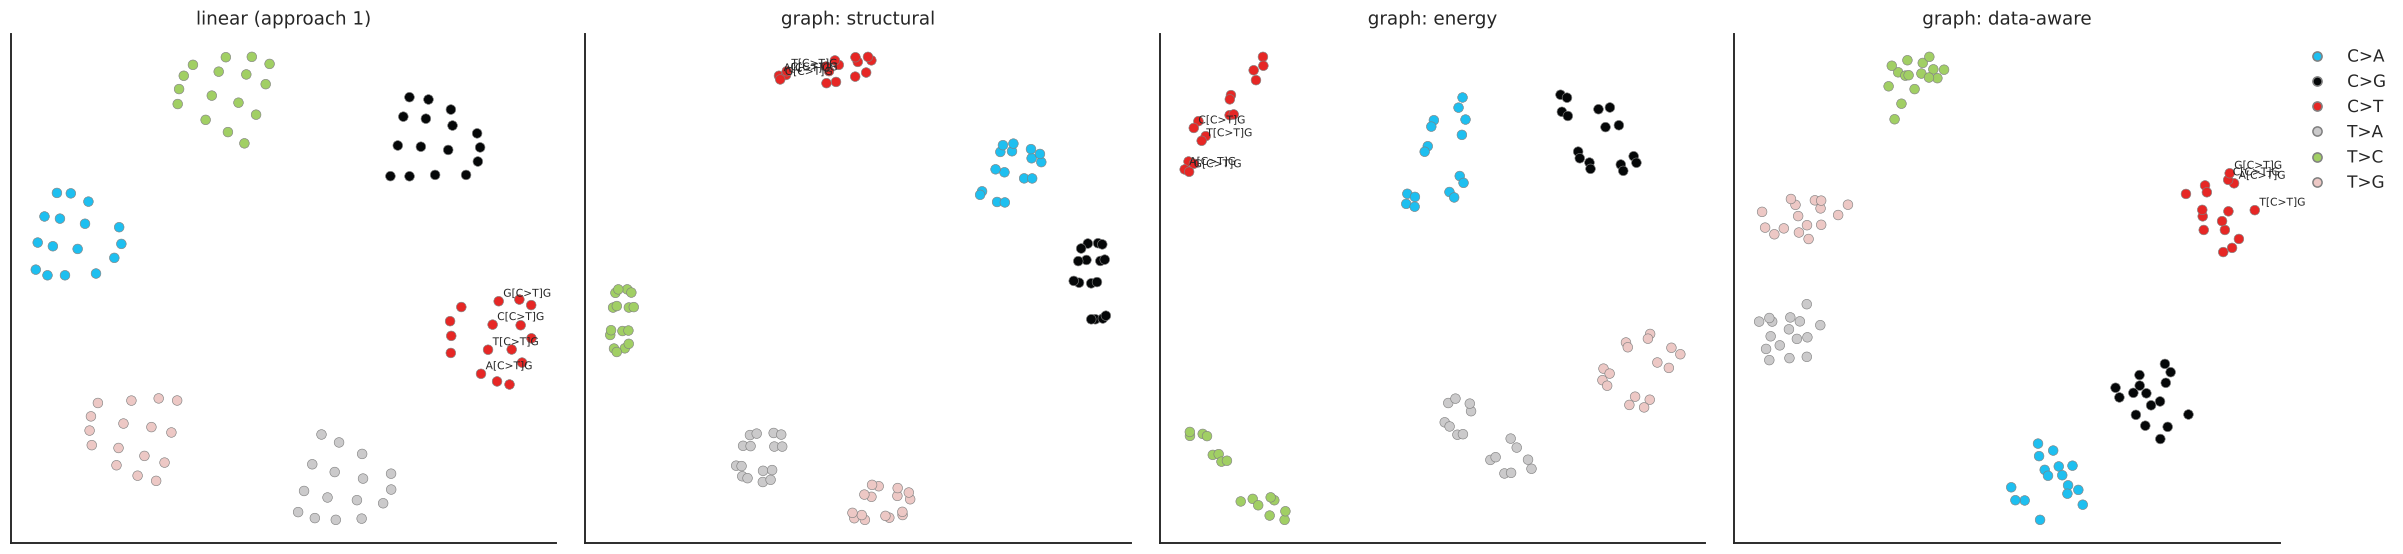

In [15]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning, module="sklearn")

fig, axes = plt.subplots(1, 4, figsize=(22, 5.2))
for ax, (k, C) in zip(axes, COSTS.items()):
    Z = MDS(n_components=2, dissimilarity="precomputed", random_state=0, n_init=4).fit_transform(C.values)
    ax.scatter(Z[:, 0], Z[:, 1], c=[SUB_COLORS[s] for s in SUB_OF], s=40, edgecolor="grey", linewidth=0.4)
    for i in np.flatnonzero(channels.three.eq("G") & channels["sub"].eq("C>T")):
        ax.annotate(CHANNELS[i], Z[i], fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set(title=k, xticks=[], yticks=[])
handles = [plt.Line2D([], [], marker="o", ls="", color=SUB_COLORS[s], markeredgecolor="grey", label=s) for s in SUBS]
axes[-1].legend(handles=handles, frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()

### 7.2 What the cost does to signature distances

Entropic OT (Sinkhorn, log-domain, numpy only) between a few COSMIC v3.6 signatures, with each cost scaled to max 1. Unlike 1 − cosine, which saturates near 1 for almost every pair, the OT distances are graded. They measure how far mass has to travel, so signatures dominated by the same substitution class look close even with different aetiologies (SBS2 vs SBS7a, both C>T), while the APOBEC pair SBS2/SBS13 stays apart because SBS13 is C>G. The graph costs give SBS2/SBS13 a smaller distance than approach 1 because C>T→C>G is a direct edge there.

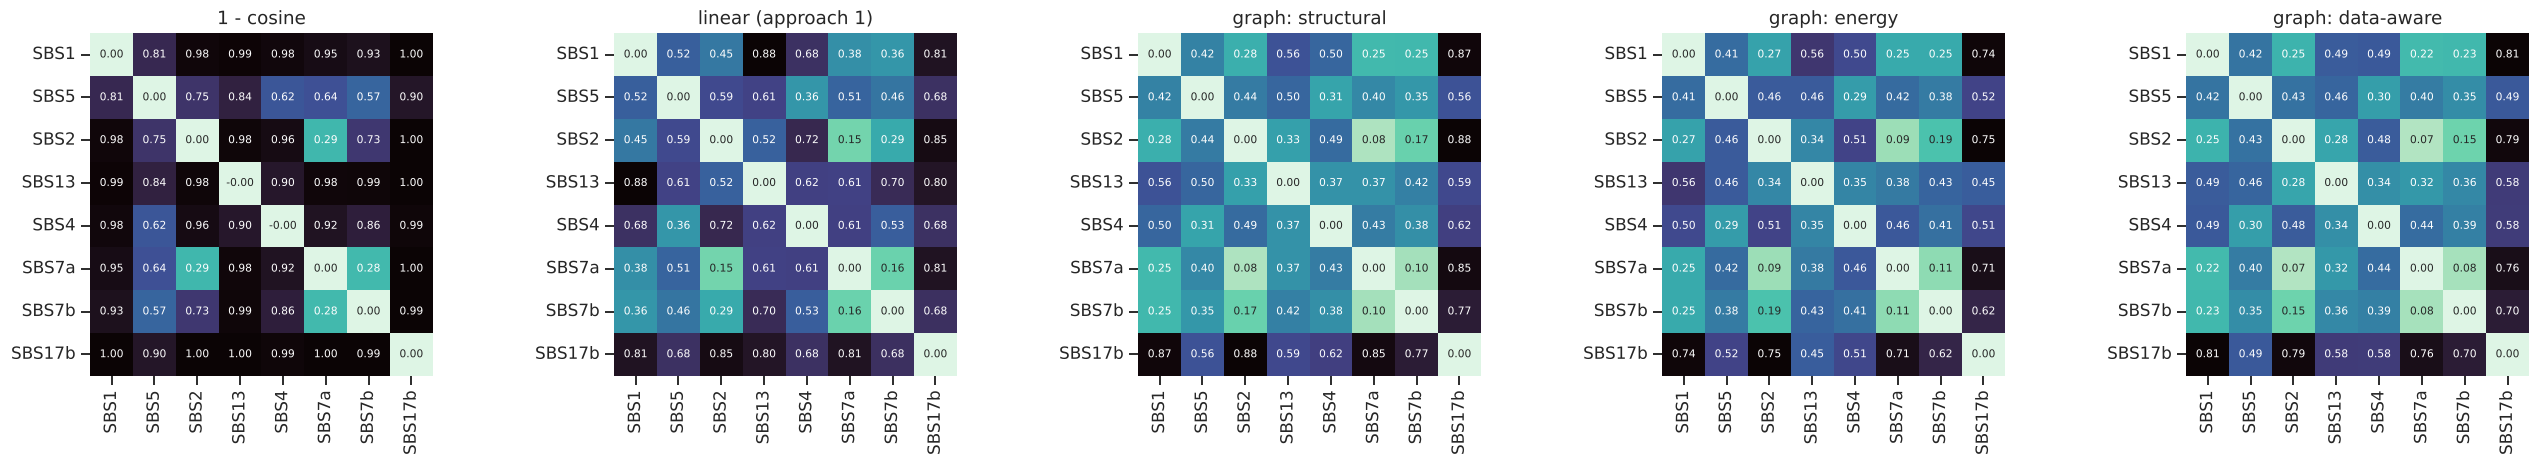

In [16]:
def sinkhorn(a, b, C, eps=0.01, n_iter=2000):
    # log-domain Sinkhorn; returns <T, C> for the entropic plan T
    la, lb = np.log(a), np.log(b)
    f = np.zeros_like(a); g = np.zeros_like(b)
    K = -C / eps
    for _ in range(n_iter):
        f = eps * (la - np.logaddexp.reduce(K + g[None, :] / eps, axis=1))
        g = eps * (lb - np.logaddexp.reduce(K + f[:, None] / eps, axis=0))
    T = np.exp(K + f[:, None] / eps + g[None, :] / eps)
    return float((T * C).sum())


cosmic = pd.read_csv(DATA / "COSMIC" / "COSMIC_v3.6_SBS_GRCh37.txt", sep="\t", index_col=0).loc[CHANNELS]
SIGS = ["SBS1", "SBS5", "SBS2", "SBS13", "SBS4", "SBS7a", "SBS7b", "SBS17b"]
Wsig = cosmic[SIGS].values + 1e-10
Wsig = Wsig / Wsig.sum(0)

Wn = Wsig / np.linalg.norm(Wsig, axis=0)
tables = {"1 - cosine": pd.DataFrame(1 - Wn.T @ Wn, index=SIGS, columns=SIGS)}
for k, C in COSTS.items():
    Cn = C.values / C.values.max()
    tables[k] = pd.DataFrame([[sinkhorn(Wsig[:, i], Wsig[:, j], Cn) if i != j else 0.0
                               for j in range(len(SIGS))] for i in range(len(SIGS))], index=SIGS, columns=SIGS)

fig, axes = plt.subplots(1, 5, figsize=(24, 4.3))
for ax, (k, T) in zip(axes, tables.items()):
    sns.heatmap(T, ax=ax, cmap="mako_r", annot=True, fmt=".2f", annot_kws={"fontsize": 7}, cbar=False, square=True)
    ax.set_title(k)
plt.tight_layout()

## 8. Save

Costs are saved in the canonical `CHANNELS` order (same as `01_EDA`), both raw and scaled to max 1 (the usual scale for Sinkhorn with a fixed ε). The edge lists and parameters are saved too, so the graph can be rebuilt or inspected.

In [17]:
for tag, C in {"linear": C_linear, "graph_struct": C_struct, "graph_energy": C_energy, "graph_data": C_data}.items():
    C.to_csv(OUT / f"C_{tag}.csv")
    (C / C.values.max()).to_csv(OUT / f"C_{tag}_scaled.csv")
E_struct.to_csv(OUT / "edges_graph_struct.csv", index=False)
E_data.to_csv(OUT / "edges_graph_data.csv", index=False)
E_energy.to_csv(OUT / "edges_graph_energy.csv", index=False)
PARAMS["energy"] = {"source": source, "ROLE_WEIGHT": ROLE_WEIGHT, "SYMMETRIZE": SYMMETRIZE,
                    "tables": {r: energy[r].to_dict() for r in ROLES},
                    "sub_energy": None if sub_energy is None else sub_energy.to_dict()}
(OUT / "params.json").write_text(json.dumps(PARAMS, indent=2))
sorted(p.name for p in OUT.iterdir())

['C_graph_data.csv',
 'C_graph_data_scaled.csv',
 'C_graph_energy.csv',
 'C_graph_energy_scaled.csv',
 'C_graph_struct.csv',
 'C_graph_struct_scaled.csv',
 'C_linear.csv',
 'C_linear_scaled.csv',
 'edges_graph_data.csv',
 'edges_graph_energy.csv',
 'edges_graph_struct.csv',
 'params.json']

**Using it in NMF-OT**

```python
C = pd.read_csv("data/cost_matrix/C_graph_struct_scaled.csv", index_col=0)
assert C.index.equals(X.index)   # X must be in the canonical CHANNELS order
```

**Knobs worth exploring**

- `W_SUB / W_FLANK` sets how much the substitution type dominates the flanks; it has the largest effect on recovered signatures.
- `CPG_FACTOR > 1` keeps NCG>NTG (SBS1-like) mass from leaking into other C>T contexts.
- Energy tables (§5) replace the hand-set multipliers; `SYMMETRIZE=None` keeps direction-dependent costs.
- `LAMBDA` blends in data-driven geometry; `K_EXTRA > 0` adds shortcut edges between strongly co-varying, non-adjacent channels (most departure from approach 1, least interpretable).